# Task 1 (General Object Detection) — Rank 1 Commercial Model Test: `RF-DETR-M`

**Objective:** Verify `RF-DETR` (`RFDETRMedium`, **Apache-2.0**) end-to-end on `f:\IRIS\surveillance-new`:
1. Run real PyTorch inference and measure latency on local IRIS calibration frames (`perception/models/DeepStream-Yolo/calib_images/*.jpg`).
2. Audit **actual** IRIS codebase integration requirements (`nvdsparsebbox_Yolo.cpp`, `config_infer_primary_yolo11_x.txt`, `labels.txt`, downstream `operate-on-class-ids=0` SGIEs, `perception/pipeline/sidecar.yaml`, `perception/engine/engine_path.py`, and `perception/engine/model_manifest.py`).
3. Export a drop-in DeepStream ONNX (`[batch, 300, 6]` = `[bx1, by1, bx2, by2, score, class_id]`) with **baked ImageNet normalization** and **COCO-91 → COCO-80 remapping (`0 = person`)** using `dynamo=False` and pure standard ONNX ops (no custom TensorRT plugins required).
4. Validate `onnxruntime-gpu` (`CUDAExecutionProvider` + `batch=1` & `batch=4`), exact numerical parity against PyTorch, IRIS's ported `decodeTensorYolo` parser, and `nvinfer` config / `engine_path` compatibility.


In [1]:
import importlib.metadata
import os
import re
import sys
import time
from copy import deepcopy
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import onnx
import onnxruntime as ort
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from rfdetr import RFDETRMedium
from rfdetr.assets.coco_classes import COCO_CLASSES
from rfdetr.export._runtime.preprocess import IMAGENET_MEAN, IMAGENET_STD

def find_repo_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "perception" / "engine" / "engine_path.py").is_file():
            return p
    raise FileNotFoundError("Could not locate IRIS repository root from " + str(start))

REPO_ROOT = find_repo_root(Path.cwd().resolve())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

CALIB_DIR = REPO_ROOT / "perception" / "models" / "DeepStream-Yolo" / "calib_images"
LABELS_PATH = REPO_ROOT / "perception" / "models" / "DeepStream-Yolo" / "labels.txt"
ARTIFACT_DIR = REPO_ROOT / "notebooks" / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

calib_images = sorted(CALIB_DIR.glob("*.jpg"))
iris_labels = [line.strip() for line in LABELS_PATH.read_text(encoding="utf-8").splitlines() if line.strip()]

print(f"Repo root          : {REPO_ROOT}")
print(f"PyTorch            : {torch.__version__} | CUDA: {torch.cuda.is_available()}"
      + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else ""))
print(f"rfdetr             : {importlib.metadata.version('rfdetr')} (Apache-2.0)")
print(f"ONNX / ORT         : {onnx.__version__} / {ort.__version__}")
print(f"ORT providers      : {ort.get_available_providers()}")
print(f"Local calib frames : {len(calib_images)} JPEG images in {CALIB_DIR.relative_to(REPO_ROOT)}")
print(f"IRIS labels.txt    : {len(iris_labels)} classes (0={iris_labels[0]!r}, 2={iris_labels[2]!r})")
assert len(calib_images) > 0, "Expected calibration images in DeepStream-Yolo/calib_images/"
assert len(iris_labels) == 80 and iris_labels[0] == "person"


F:\IRIS\surveillance-new\notebooks\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
F:\IRIS\surveillance-new\notebooks\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


F:\IRIS\surveillance-new\notebooks\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Repo root          : F:\IRIS\surveillance-new
PyTorch            : 2.14.1+cu130 | CUDA: True (Quadro RTX 3000)
rfdetr             : 1.12.1 (Apache-2.0)
ONNX / ORT         : 1.23.2 / 1.32.0
ORT providers      : ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
Local calib frames : 60 JPEG images in perception\models\DeepStream-Yolo\calib_images
IRIS labels.txt    : 80 classes (0='person', 2='car')


## 1. Native PyTorch Inference (`RFDETRMedium`) on Real IRIS Surveillance Frames

We test `RFDETRMedium` (`resolution=576`, Apache-2.0 weights downloaded and MD5-checked automatically by `rfdetr`) on 4 representative frames from `calib_images/`:
- `frame_00014.jpg` (multi-person corridor)
- `frame_00041.jpg` (3 people + `backpack`)
- `frame_00051.jpg` (crowded scene: 9 people + `umbrella`)
- `frame_00055.jpg` (8 detections: people + `umbrella`)


[2026-11-16 13:56:05] [INFO] rf-detr - File C:\Users\Maha Mamdouh\.roboflow\models\rf-detr-medium.pth already exists with correct MD5 hash.


[2026-11-16 13:56:07] [INFO] rf-detr - File C:\Users\Maha Mamdouh\.roboflow\models\rf-detr-medium.pth already exists with correct MD5 hash.


Loaded RFDETRMedium: resolution=576x576, num_classes=90, class_names type=list (len=80)


[2026-11-16 13:56:09] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).


  frame_00014.jpg | size=(1080, 720) | dets= 5 |   79.3 ms | classes=['person', 'person', 'person', 'person', 'person']
  frame_00041.jpg | size=(1080, 720) | dets= 4 |   80.5 ms | classes=['person', 'person', 'person', 'backpack']
  frame_00051.jpg | size=(1080, 720) | dets=10 |   79.2 ms | classes=['person', 'person', 'person', 'person', 'umbrella', 'person', 'person', 'person', 'person', 'person']


  frame_00055.jpg | size=(1080, 720) | dets= 8 |   54.7 ms | classes=['person', 'person', 'person', 'person', 'umbrella', 'umbrella', 'person', 'person']


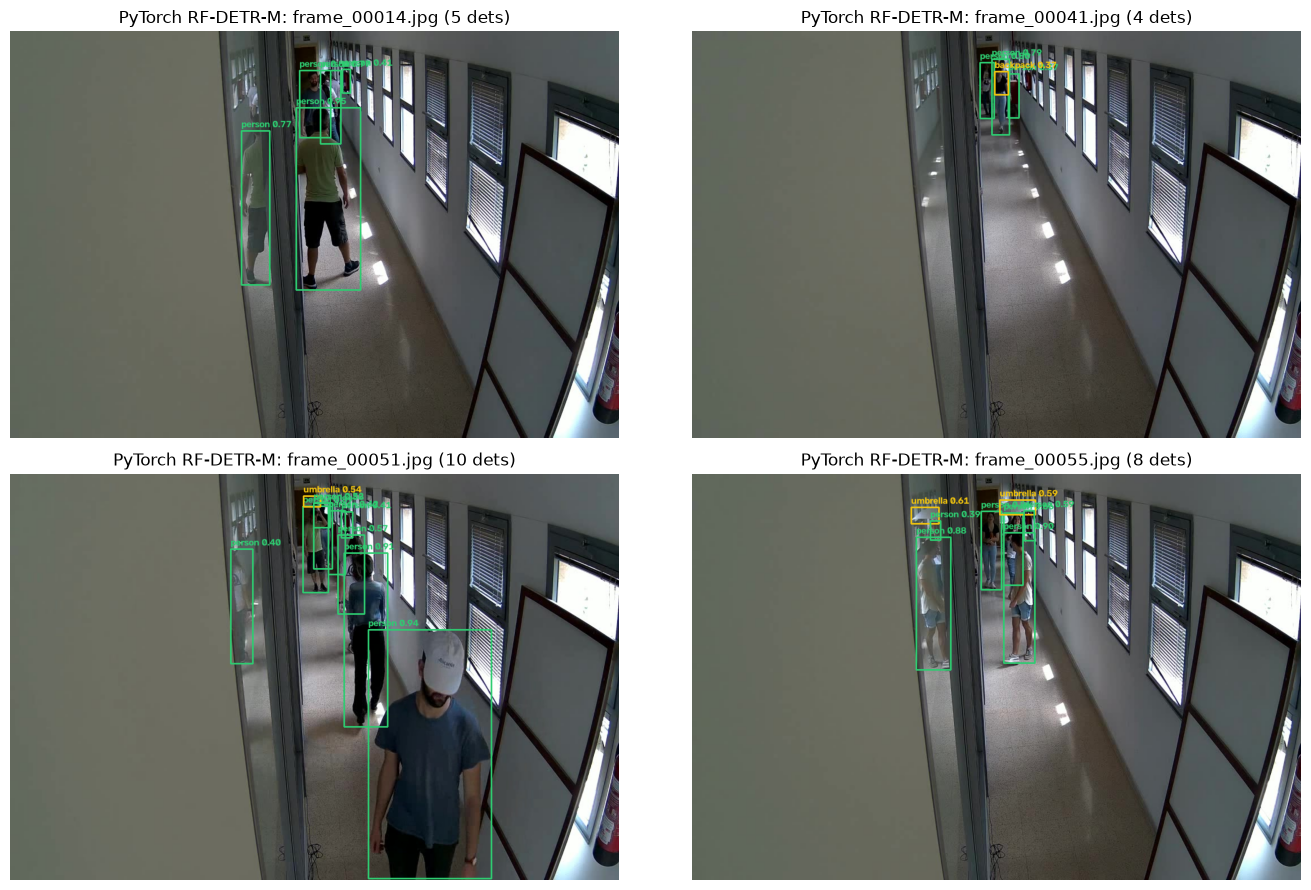

In [2]:
SAMPLE_NAMES = ["frame_00014.jpg", "frame_00041.jpg", "frame_00051.jpg", "frame_00055.jpg"]
SAMPLE_PATHS = [CALIB_DIR / name for name in SAMPLE_NAMES]
CONF_THRESH = 0.35

pt_model = RFDETRMedium()
IMG_RES = int(pt_model.model_config.resolution)
print(f"Loaded RFDETRMedium: resolution={IMG_RES}x{IMG_RES}, num_classes={pt_model.model_config.num_classes}, "
      f"class_names type={type(pt_model.class_names).__name__} (len={len(pt_model.class_names)})")

# Warmup + timed PyTorch predict
_ = pt_model.predict(Image.open(SAMPLE_PATHS[0]).convert("RGB"), threshold=CONF_THRESH)
if torch.cuda.is_available():
    torch.cuda.synchronize()

pt_results = {}
pt_latencies_ms = []
for p in SAMPLE_PATHS:
    im = Image.open(p).convert("RGB")
    t0 = time.perf_counter()
    det = pt_model.predict(im, threshold=CONF_THRESH)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    pt_latencies_ms.append((time.perf_counter() - t0) * 1000.0)
    names = [COCO_CLASSES[int(c)] for c in det.class_id]
    pt_results[p.name] = (im, det, names)
    print(f"  {p.name:15s} | size={im.size} | dets={len(det):2d} | {pt_latencies_ms[-1]:6.1f} ms | classes={names}")

# Visualize 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, name in zip(axes.flat, SAMPLE_NAMES):
    im, det, cls_names = pt_results[name]
    canvas = np.array(im).copy()
    for (x1, y1, x2, y2), conf, cname in zip(det.xyxy, det.confidence, cls_names):
        p1, p2 = (int(round(x1)), int(round(y1))), (int(round(x2)), int(round(y2)))
        color = (46, 204, 113) if cname == "person" else (241, 196, 15)
        cv2.rectangle(canvas, p1, p2, color, 2)
        cv2.putText(canvas, f"{cname} {conf:.2f}", (p1[0], max(18, p1[1] - 6)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2, cv2.LINE_AA)
    ax.imshow(canvas)
    ax.set_title(f"PyTorch RF-DETR-M: {name} ({len(det)} dets)")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 2. IRIS Codebase Compatibility Audit (Actual Files)

Before exporting ONNX, we inspect the real C++, Python, and config contracts in `f:\IRIS\surveillance-new`:

| Integration Point | What the IRIS Codebase Expects | Native `RF-DETR.export()` Behavior | Drop-in Status / Fix |
|---|---|---|---|
| **C++ BBox Parser** (`nvdsparsebbox_Yolo.cpp`) | Single output tensor `[N, 6]` = `[bx1, by1, bx2, by2, score, class_id]` in pixel coords | 2 outputs (`dets [B, 300, 4]` norm `cxcywh`, `labels [B, 300, 91]` logits) | Needs `[B, 300, 6]` DeepStream output head (reproduces `DeepStream-Yolo/utils/export_rfdetr.py` formula) |
| **Upstream `export_rfdetr.py`** | Expects `rfdetr.class_names` dict & external `F` / `ms_deform_attn_core_pytorch` | `rfdetr==1.12.1` uses `list` for `class_names` and pure-PyTorch `grid_sample` (`0` custom ops) | Upstream DeepStream script breaks without patching; our wrapper exports directly via pure ONNX ops |
| **Pixel Normalization** (`nvinfer`) | Scalar `net-scale-factor=1/255` (`0.00392156979`), RGB (`model-color-format=0`) | Requires per-channel ImageNet `(x - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]` | Bake ImageNet `(x - mean) / std` inside ONNX graph input! |
| **Downstream SGIEs & `labels.txt`** | `labels.txt` (80 COCO classes, **`0 = person`**); `config_sgie_face.txt`, `config_sgie_pose.txt`, `config_infer_ppe.txt` hardcode **`operate-on-class-ids=0`** | Raw RF-DETR emits COCO-91 where **`0 = background` and `1 = person`** | Select the 80 valid COCO-91 logit indices (`[1, 2, ..., 90]`) in ONNX so **`0 = person`** stays intact! |
| **Engine Cache Naming** (`engine_path.py`) | `engine-create-func-name` forces `<cwd>/model_b*.engine` collision branch | Upstream `config_infer_primary_rfdetr.txt` includes `engine-create-func-name=NvDsInferYoloCudaEngineGet` | Omit `engine-create-func-name` in `nvinfer` config so ONNX builds unique `<onnx>_b*_gpu*_fp*.engine` |


In [3]:
# Verify actual repo files programmatically
cpp_path = REPO_ROOT / "perception" / "models" / "DeepStream-Yolo" / "nvdsinfer_custom_impl_Yolo" / "nvdsparsebbox_Yolo.cpp"
cpp_text = cpp_path.read_text(encoding="utf-8")
has_decode_yolo = "decodeTensorYolo(" in cpp_text and "NvDsInferParseCustomYolo(" in cpp_text
has_rfdetr_stride_note = "b * 6 + 4" in cpp_text or "output[b * 6" in cpp_text

sgie_configs = [
    REPO_ROOT / "perception" / "models" / "DeepStream-Yolo-Face" / "config_sgie_face.txt",
    REPO_ROOT / "perception" / "models" / "DeepStream-Yolo-Pose" / "config_sgie_pose.txt",
    REPO_ROOT / "perception" / "models" / "DeepStream-Yolo-PPE" / "config_infer_ppe.txt",
    REPO_ROOT / "perception" / "models" / "DeepStream-Yolo" / "config_sgie_plate.txt",
    REPO_ROOT / "products" / "concealment_detection" / "config_sgie_pose.txt",
]
op_class_ids = {}
for cfg_p in sgie_configs:
    m = re.search(r"^operate-on-class-ids\s*=\s*(.+)$", cfg_p.read_text(encoding="utf-8"), re.M)
    op_class_ids[str(cfg_p.relative_to(REPO_ROOT))] = m.group(1).strip() if m else None

print(f"nvdsparsebbox_Yolo.cpp decodeTensorYolo present : {has_decode_yolo}")
print(f"nvdsparsebbox_Yolo.cpp [N,6] stride check        : {has_rfdetr_stride_note}")
print(f"rfdetr=={importlib.metadata.version('rfdetr')} ImageNet mean/std          : mean={IMAGENET_MEAN}, std={IMAGENET_STD}")
print("Downstream SGIE operate-on-class-ids checks:")
for rel_p, cid in op_class_ids.items():
    print(f"  {rel_p:60s} -> operate-on-class-ids={cid}")

assert has_decode_yolo and has_rfdetr_stride_note
assert all(v == "0" for v in op_class_ids.values()), f"Expected all SGIEs on class 0: {op_class_ids}"


nvdsparsebbox_Yolo.cpp decodeTensorYolo present : True
nvdsparsebbox_Yolo.cpp [N,6] stride check        : True
rfdetr==1.12.1 ImageNet mean/std          : mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
Downstream SGIE operate-on-class-ids checks:
  perception\models\DeepStream-Yolo-Face\config_sgie_face.txt  -> operate-on-class-ids=0
  perception\models\DeepStream-Yolo-Pose\config_sgie_pose.txt  -> operate-on-class-ids=0
  perception\models\DeepStream-Yolo-PPE\config_infer_ppe.txt   -> operate-on-class-ids=0
  perception\models\DeepStream-Yolo\config_sgie_plate.txt      -> operate-on-class-ids=0
  products\concealment_detection\config_sgie_pose.txt          -> operate-on-class-ids=0


## 3. DeepStream-Compatible ONNX Export (`[batch, 300, 6]` + ImageNet Norm + COCO-80 Remap)

Notice how cleanly we solve every integration gap at export time in pure PyTorch/ONNX (zero custom TensorRT plugins, zero C++ edits, zero SGIE config rewrites):
1. Input: `[batch, 3, 576, 576]` RGB in **`[0.0, 1.0]`** (`net-scale-factor=0.0039215697906911373`, `model-color-format=0`).
2. Inside the ONNX graph: `(x - mean) / std` → frozen-shape `LWDETR.forward_export` → slice the 80 valid COCO-91 slots (`[1, 2, ..., 90]`) → `.sigmoid()` + `max` → convert `cxcywh` normalized boxes to `[bx1, by1, bx2, by2]` pixel coordinates → **`output: [batch, 300, 6]`**.


In [4]:
COCO91_TO_80_INDICES = sorted(COCO_CLASSES.keys())  # [1, 2, ..., 90] -> 0='person', 2='car', ...

class DeepStreamRFDETR(nn.Module):
    def __init__(self, core_model: nn.Module, img_h: int, img_w: int, bake_imagenet_norm: bool = True):
        super().__init__()
        self.core = core_model
        self.img_h = int(img_h)
        self.img_w = int(img_w)
        self.bake_imagenet_norm = bake_imagenet_norm
        self.register_buffer("mean", torch.tensor(IMAGENET_MEAN, dtype=torch.float32).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(IMAGENET_STD, dtype=torch.float32).view(1, 3, 1, 1))
        self.register_buffer("coco_idx", torch.tensor(COCO91_TO_80_INDICES, dtype=torch.long))
        self.register_buffer(
            "convert_matrix",
            torch.tensor([[1, 0, 1, 0], [0, 1, 0, 1], [-0.5, 0, 0.5, 0], [0, -0.5, 0, 0.5]], dtype=torch.float32),
        )
        self.register_buffer(
            "scale_xyxy",
            torch.tensor([[[self.img_w, self.img_h, self.img_w, self.img_h]]], dtype=torch.float32),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if self.bake_imagenet_norm:
            x = (x - self.mean) / self.std
        boxes, logits = self.core(x)[:2]
        boxes_xyxy = (boxes @ self.convert_matrix) * self.scale_xyxy
        logits_80 = logits.index_select(-1, self.coco_idx)
        scores, labels = torch.max(logits_80.sigmoid(), dim=-1, keepdim=True)
        return torch.cat([boxes_xyxy, scores, labels.to(boxes_xyxy.dtype)], dim=-1)

# Export cleanly on CPU using deepcopy + model.export() (dynamo=False, matching mtmc/export_vehicle_onnx.py)
core_export = deepcopy(pt_model.model.model).cpu().eval()
if hasattr(core_export, "export"):
    core_export.export()

ds_wrapper = DeepStreamRFDETR(core_export, IMG_RES, IMG_RES, bake_imagenet_norm=True).eval()
ONNX_PATH = ARTIFACT_DIR / "rfdetr-medium-ds.onnx"
dummy = torch.zeros(1, 3, IMG_RES, IMG_RES, dtype=torch.float32)

t0 = time.perf_counter()
torch.onnx.export(
    ds_wrapper,
    dummy,
    str(ONNX_PATH),
    input_names=["input"],
    output_names=["output"],
    export_params=True,
    keep_initializers_as_inputs=False,
    do_constant_folding=True,
    opset_version=17,
    dynamic_axes={"input": {0: "batch"}, "output": {0: "batch"}},
    dynamo=False,
)
export_s = time.perf_counter() - t0

onnx_model = onnx.load(str(ONNX_PATH))
onnx.checker.check_model(onnx_model)
custom_domains = {n.domain for n in onnx_model.graph.node if n.domain}
inputs_meta = [(i.name, [d.dim_param or d.dim_value for d in i.type.tensor_type.shape.dim]) for i in onnx_model.graph.input]
outputs_meta = [(o.name, [d.dim_param or d.dim_value for d in o.type.tensor_type.shape.dim]) for o in onnx_model.graph.output]

print(f"Exported ONNX   : {ONNX_PATH.relative_to(REPO_ROOT)} ({ONNX_PATH.stat().st_size / 1e6:.2f} MB in {export_s:.1f}s)")
print(f"onnx.checker    : PASSED")
print(f"Inputs          : {inputs_meta}")
print(f"Outputs         : {outputs_meta}")
print(f"Graph nodes     : {len(onnx_model.graph.node)} | custom domains: {custom_domains}")
assert not custom_domains, f"Unexpected non-standard ONNX domains: {custom_domains}"


C:\Users\Maha Mamdouh\AppData\Local\Temp\ipykernel_27976\2510617913.py:41: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(
F:\IRIS\surveillance-new\notebooks\.venv\Lib\site-packages\rfdetr\models\backbone\dinov2.py:279: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  assert x.shape[2] % block_size == 0 and x.shape[3] % block_size == 0, (
F:\IRIS\surveillance-new\notebooks\.venv\Lib\site-packages\rfdetr\models\backbone\dinov2

F:\IRIS\surveillance-new\notebooks\.venv\Lib\site-packages\rfdetr\models\backbone\__init__.py:55: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if cross_attn_feats is None and pos.ndim == 4 and pos.shape[1] == 1:
F:\IRIS\surveillance-new\notebooks\.venv\Lib\site-packages\rfdetr\models\transformer.py:1031: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  topk = min(self.num_queries, enc_outputs_class_unselected_gidx.shape[-2])
F:\IRIS\surveillance-new\notebooks\.venv\Lib\site-packages\rfdetr\models\transformer.py:1140: TracerWarning: Converting a tensor to

F:\IRIS\surveillance-new\notebooks\.venv\Lib\site-packages\rfdetr\models\ops\functions\ms_deform_attn_func.py:78: TracerWarning: Converting a tensor to a Python integer might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  value_l_ = value_list[level_index].view(batch_size * n_heads, head_dim, int(height), int(width))


Exported ONNX   : notebooks\artifacts\rfdetr-medium-ds.onnx (121.14 MB in 3.8s)
onnx.checker    : PASSED
Inputs          : [('input', ['batch', 3, 576, 576])]
Outputs         : [('output', ['batch', 'Concatoutput_dim_1', 6])]
Graph nodes     : 3247 | custom domains: set()


## 4. Exact IRIS `decodeTensorYolo` Simulation, ORT CUDA Inference & Parity Check

Here we load `rfdetr-medium-ds.onnx` into `onnxruntime-gpu` (`CUDAExecutionProvider`) and simulate the **exact** DeepStream C++ + Python pipeline:
1. Resize `[H, W]` -> `[576, 576]` bilinear (`maintain-aspect-ratio=0`), scale by `1/255` (`net-scale-factor=0.0039215697906911373`).
2. Run ORT CUDA on **both `batch=1` and `batch=4`** (verifying multi-camera dynamic batching has zero drift between batch slots).
3. Decode `[300, 6]` using an exact Python port of `convertBBox` + `decodeTensorYolo` from `nvdsparsebbox_Yolo.cpp#L60-L96`.
4. Rescale boxes back to capture resolution (`1080x720`), apply IRIS `labels.txt` + `relevant_classes = {"person"}` (`perception/pipeline/sidecar.yaml`), and measure numerical parity against native PyTorch!


In [5]:
def decode_tensor_yolo_python(
    output: np.ndarray,
    net_w: int,
    net_h: int,
    num_classes: int,
    threshold: float = 0.35,
):
    """Exact port of convertBBox + decodeTensorYolo in
    perception/models/DeepStream-Yolo/nvdsinfer_custom_impl_Yolo/nvdsparsebbox_Yolo.cpp#L60-L96
    for a single frame slice of shape (300, 6): [bx1, by1, bx2, by2, maxProb, maxIndex]."""
    binfo = []
    for row in output:
        bx1, by1, bx2, by2, max_prob, max_idx_f = row
        if max_prob < threshold:
            continue
        max_idx = int(max_idx_f)
        if max_idx >= num_classes or max_idx < 0:
            continue
        # convertBBox(..., netW, netH)
        x1 = float(np.clip(bx1, 0.0, net_w - 1.0))
        y1 = float(np.clip(by1, 0.0, net_h - 1.0))
        x2 = float(np.clip(bx2, 0.0, net_w - 1.0))
        y2 = float(np.clip(by2, 0.0, net_h - 1.0))
        w = float(np.clip(x2 - x1, 0.0, net_w - 1.0))
        h = float(np.clip(y2 - y1, 0.0, net_h - 1.0))
        binfo.append({"left": x1, "top": y1, "width": w, "height": h, "classId": max_idx, "detectionConfidence": float(max_prob)})
    return binfo

def preprocess_like_nvinfer(pil_img: Image.Image, res: int) -> np.ndarray:
    arr = np.asarray(pil_img.convert("RGB"), dtype=np.uint8).copy()
    t = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).float() * 0.0039215697906911373
    t = F.interpolate(t, size=(res, res), mode="bilinear", align_corners=False, antialias=False)
    return t.numpy()

sess = ort.InferenceSession(str(ONNX_PATH), providers=["CUDAExecutionProvider", "CPUExecutionProvider"])
in_name = sess.get_inputs()[0].name
print("Active ORT providers:", sess.get_providers())

# Warmup ORT
sample_batch = np.concatenate([preprocess_like_nvinfer(Image.open(p), IMG_RES) for p in SAMPLE_PATHS], axis=0)
_ = sess.run(["output"], {in_name: sample_batch[:1]})
_ = sess.run(["output"], {in_name: sample_batch})

# Check batch=1 parity and batch=4 consistency
max_score_diffs = []
max_coord_diffs = []
parsed_outputs = {}

batch_out = sess.run(["output"], {in_name: sample_batch})[0]
print(f"Batch=4 ORT output shape: {batch_out.shape}")

for i, name in enumerate(SAMPLE_NAMES):
    im, pt_det, pt_names = pt_results[name]
    orig_w, orig_h = im.size
    single_out = sess.run(["output"], {in_name: sample_batch[i:i+1]})[0]
    kept_mask = single_out[0, :, 4] >= CONF_THRESH
    batch_box_diff = float(np.max(np.abs(single_out[0, kept_mask, :4] - batch_out[i, kept_mask, :4])))
    batch_score_diff = float(np.max(np.abs(single_out[0, kept_mask, 4] - batch_out[i, kept_mask, 4])))
    assert np.array_equal(single_out[0, kept_mask, 5], batch_out[i, kept_mask, 5])
    binfo = decode_tensor_yolo_python(single_out[0], IMG_RES, IMG_RES, len(iris_labels), threshold=CONF_THRESH)
    # Sort descending by confidence to align with supervision predict() ordering
    binfo.sort(key=lambda d: d["detectionConfidence"], reverse=True)
    ort_scores = np.array([d["detectionConfidence"] for d in binfo], dtype=np.float32)
    ort_classes = [iris_labels[d["classId"]] for d in binfo]
    ort_xyxy = np.array(
        [[d["left"] * orig_w / IMG_RES, d["top"] * orig_h / IMG_RES,
          (d["left"] + d["width"]) * orig_w / IMG_RES, (d["top"] + d["height"]) * orig_h / IMG_RES]
         for d in binfo],
        dtype=np.float32,
    ) if binfo else np.zeros((0, 4), dtype=np.float32)

    score_diff = float(np.max(np.abs(np.sort(pt_det.confidence) - np.sort(ort_scores))))
    coord_diff = float(np.max(np.abs(np.sort(pt_det.xyxy, axis=0) - np.sort(ort_xyxy, axis=0))))
    assert batch_box_diff < 1e-3 and batch_score_diff < 1e-4
    max_score_diffs.append(score_diff)
    max_coord_diffs.append(coord_diff)
    parsed_outputs[name] = (binfo, ort_xyxy, ort_scores, ort_classes)

    person_triggers = sum(1 for d in binfo if d["classId"] == 0)  # sgie_face/pose operate-on-class-ids=0
    print(f"  {name:15s} | dets={len(binfo):2d} | SGIE(id=0 'person')={person_triggers:2d} | "
          f"b1vs4_box={batch_box_diff:.2e}px b1vs4_score={batch_score_diff:.2e} | "
          f"pt_score_diff={score_diff:.2e} | pt_box_diff={coord_diff:.3f}px")

assert max(max_score_diffs) < 1e-4, f"Score parity failure: {max_score_diffs}"
assert max(max_coord_diffs) < 0.05, f"Box coord parity failure: {max_coord_diffs}"


Active ORT providers: ['CUDAExecutionProvider', 'CPUExecutionProvider']


Batch=4 ORT output shape: (4, 300, 6)
  frame_00014.jpg | dets= 5 | SGIE(id=0 'person')= 5 | b1vs4_box=9.16e-05px b1vs4_score=1.97e-06 | pt_score_diff=1.91e-06 | pt_box_diff=0.000px
  frame_00041.jpg | dets= 4 | SGIE(id=0 'person')= 3 | b1vs4_box=8.01e-05px b1vs4_score=4.86e-06 | pt_score_diff=2.35e-06 | pt_box_diff=0.000px
  frame_00051.jpg | dets=10 | SGIE(id=0 'person')= 9 | b1vs4_box=6.10e-05px b1vs4_score=4.23e-06 | pt_score_diff=3.40e-06 | pt_box_diff=0.000px
  frame_00055.jpg | dets= 8 | SGIE(id=0 'person')= 6 | b1vs4_box=3.05e-05px b1vs4_score=8.94e-07 | pt_score_diff=1.13e-06 | pt_box_diff=0.000px


ORT CUDA benchmark (60 real IRIS calib_images @ 576x576):
  Batch=1 : 44.23 ms/frame (22.6 FPS)
  Batch=4 : 40.36 ms/frame (24.8 FPS)
  Total dets across 60 frames: 221 (person=212, other=9)


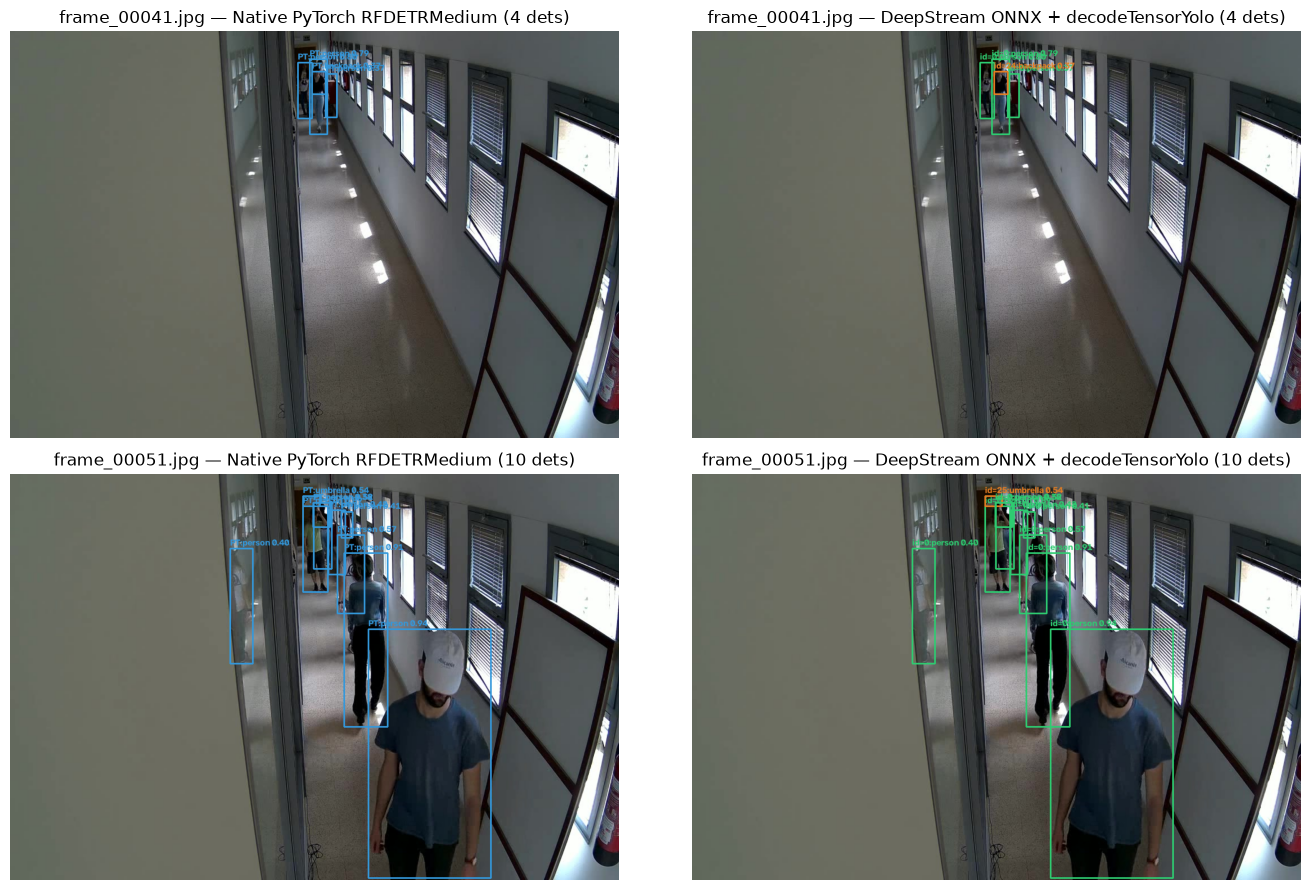

In [6]:
# Benchmark ONNX Runtime CUDA latency across all 60 calibration frames (batch=1 vs batch=4)
all_inputs = [preprocess_like_nvinfer(Image.open(p), IMG_RES) for p in calib_images]

t0 = time.perf_counter()
det_counts = []
person_counts = []
for x1 in all_inputs:
    y = sess.run(["output"], {in_name: x1})[0][0]
    binfo = decode_tensor_yolo_python(y, IMG_RES, IMG_RES, len(iris_labels), threshold=CONF_THRESH)
    det_counts.append(len(binfo))
    person_counts.append(sum(1 for d in binfo if iris_labels[d["classId"]] == "person"))
t_b1 = time.perf_counter() - t0

t0 = time.perf_counter()
for i in range(0, len(all_inputs), 4):
    xb = np.concatenate(all_inputs[i:i+4], axis=0)
    _ = sess.run(["output"], {in_name: xb})
t_b4 = time.perf_counter() - t0

print(f"ORT CUDA benchmark ({len(calib_images)} real IRIS calib_images @ {IMG_RES}x{IMG_RES}):")
print(f"  Batch=1 : {t_b1 / len(all_inputs) * 1000:.2f} ms/frame ({len(all_inputs) / t_b1:.1f} FPS)")
print(f"  Batch=4 : {t_b4 / len(all_inputs) * 1000:.2f} ms/frame ({len(all_inputs) / t_b4:.1f} FPS)")
print(f"  Total dets across 60 frames: {sum(det_counts)} (person={sum(person_counts)}, other={sum(det_counts)-sum(person_counts)})")

# Side-by-side comparison plot on frame_00051.jpg (crowded) & frame_00041.jpg (person + backpack)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row_idx, name in enumerate(["frame_00041.jpg", "frame_00051.jpg"]):
    im, pt_det, pt_names = pt_results[name]
    binfo, ort_xyxy, ort_scores, ort_classes = parsed_outputs[name]

    c_pt = np.array(im).copy()
    for (x1, y1, x2, y2), conf, cname in zip(pt_det.xyxy, pt_det.confidence, pt_names):
        cv2.rectangle(c_pt, (int(x1), int(y1)), (int(x2), int(y2)), (52, 152, 219), 2)
        cv2.putText(c_pt, f"PT:{cname} {conf:.2f}", (int(x1), max(18, int(y1)-5)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (52, 152, 219), 2)

    c_ds = np.array(im).copy()
    for d, (x1, y1, x2, y2), conf, cname in zip(binfo, ort_xyxy, ort_scores, ort_classes):
        # Green if passes relevant_classes={'person'} & triggers sgie_face (class_id=0), amber otherwise
        col = (46, 204, 113) if d["classId"] == 0 else (230, 126, 34)
        cv2.rectangle(c_ds, (int(x1), int(y1)), (int(x2), int(y2)), col, 2)
        tag = f"id={d['classId']}:{cname} {conf:.2f}"
        cv2.putText(c_ds, tag, (int(x1), max(18, int(y1)-5)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, col, 2)

    axes[row_idx, 0].imshow(c_pt)
    axes[row_idx, 0].set_title(f"{name} — Native PyTorch RFDETRMedium ({len(pt_det)} dets)")
    axes[row_idx, 0].axis("off")
    axes[row_idx, 1].imshow(c_ds)
    axes[row_idx, 1].set_title(f"{name} — DeepStream ONNX + decodeTensorYolo ({len(binfo)} dets)")
    axes[row_idx, 1].axis("off")

plt.tight_layout()
plt.show()


## 5. Validate IRIS `engine_path` / `model_manifest` / `nvinfer` Config Integration

Finally, we emit a candidate `nvinfer` PGIE config into `notebooks/artifacts/config_infer_primary_rfdetr_iris.txt` (leaving tracked `perception/` files untouched) and pass it through IRIS's **actual** Python config & manifest utilities (`perception.engine.engine_path._parse`, `perception.engine.model_manifest.ModelRef` / `NVINFER_FILE_KEYS`) to verify there are zero path-resolution, engine-collision, or label-lookup surprises.


In [7]:
from perception.engine.engine_path import _parse as parse_engine_cfg, assert_distinct_engine_paths
from perception.engine.model_manifest import NVINFER_FILE_KEYS

CANDIDATE_CFG = ARTIFACT_DIR / "config_infer_primary_rfdetr_iris.txt"
CANDIDATE_CFG.write_text(f"""[property]
gpu-id=0
net-scale-factor=0.0039215697906911373
model-color-format=0
onnx-file={ONNX_PATH.name}
model-engine-file={ONNX_PATH.name}_b1_gpu0_fp32.engine
labelfile-path=../../perception/models/DeepStream-Yolo/labels.txt
batch-size=1
network-mode=0
num-detected-classes=80
interval=0
gie-unique-id=1
process-mode=1
network-type=0
cluster-mode=4
maintain-aspect-ratio=0
parse-bbox-func-name=NvDsInferParseYolo
custom-lib-path=/opt/nvidia/deepstream/deepstream/custom_parsers/libnvdsinfer_custom_impl_Yolo.so

[class-attrs-all]
pre-cluster-threshold=0.35
topk=300
""", encoding="utf-8")

mode, onnx_rel, custom_engine, read_ok = parse_engine_cfg(str(CANDIDATE_CFG))
assert read_ok and not custom_engine, "Must NOT set engine-create-func-name (would trigger cwd collision branch)"
resolved_onnx = (CANDIDATE_CFG.parent / onnx_rel).resolve()
assert resolved_onnx.is_file()

# Verify no engine-path collision with config_sgie_face.txt
face_cfg = REPO_ROOT / "perception" / "models" / "DeepStream-Yolo-Face" / "config_sgie_face.txt"
_, face_onnx_rel, face_custom, _ = parse_engine_cfg(str(face_cfg))
pgie_eng = f"{resolved_onnx}_b1_gpu0_{mode}.engine"
sgie_eng = f"{(face_cfg.parent / face_onnx_rel).resolve()}_b16_gpu0_fp32.engine"
assert_distinct_engine_paths([("pgie", str(CANDIDATE_CFG), pgie_eng), ("sgie_face", str(face_cfg), sgie_eng)])

print("Verified perception.engine.engine_path._parse()    : PASSED")
print(f"  mode={mode}, onnx={onnx_rel}, custom_engine_branch={custom_engine}")
print(f"  derived pgie engine : {Path(pgie_eng).name}")
print(f"  assert_distinct_engine_paths(pgie + sgie_face)  : PASSED")
print(f"  NVINFER_FILE_KEYS covered                       : {NVINFER_FILE_KEYS}")
print("\nFINAL TASK 1 (RF-DETR-M) VERDICT: CODEBASE COMPATIBLE (with our IRIS ONNX wrapper + nvinfer config above).")
print("Remaining on-target check: run DeepStream 9.0 TensorRT FP16/FP32 engine build inside Linux Docker (`just`-stack) where TensorRT / libnvinfer exist.")


Verified perception.engine.engine_path._parse()    : PASSED
  mode=fp32, onnx=rfdetr-medium-ds.onnx, custom_engine_branch=False
  derived pgie engine : rfdetr-medium-ds.onnx_b1_gpu0_fp32.engine
  assert_distinct_engine_paths(pgie + sgie_face)  : PASSED
  NVINFER_FILE_KEYS covered                       : ('onnx-file', 'labelfile-path')

FINAL TASK 1 (RF-DETR-M) VERDICT: CODEBASE COMPATIBLE (with our IRIS ONNX wrapper + nvinfer config above).
Remaining on-target check: run DeepStream 9.0 TensorRT FP16/FP32 engine build inside Linux Docker (`just`-stack) where TensorRT / libnvinfer exist.
